# Extended joint discrimination

Paper §§5.2–5.3. Compare five input states and scalable allocation methods, with Greedy as the gap reference. Greedy minimizes PGM error per state; VND uses phase separation. The reference is not a certified optimum.


In [ ]:
from pathlib import Path
import sys, importlib, json
from collections import Counter
from IPython.display import display, Markdown
ROOT = Path.cwd().resolve()
if (ROOT/'problem-3-global-pgm').is_dir(): ROOT = ROOT/'problem-3-global-pgm'
assert (ROOT/'src/pgm.py').exists()
loaded = sys.modules.get('src')
if loaded and Path(loaded.__file__).resolve().parent != ROOT/'src':
    raise RuntimeError('Restart kernel: another problem uses the src package')
for name in list(sys.modules):
    if name=='src' or name.startswith('src.'): del sys.modules[name]
sys.path.insert(0,str(ROOT))
importlib.invalidate_caches()
from src.analysis import METHODS, run_analysis, select_cases
from src.reporting.publication import prepare, figures
STUDY = 'extended'
DATASET_ROOT = ROOT/'inputs'/STUDY
RUN_MODE = 'full'       # 'full' uses all cases; 'test' uses a balanced sample.
RUN_ANALYSIS = True
RESUME = True
MAX_ALLOCATIONS = 20_000  # Compact maximum is C(20,4)=4845; unused by Extended.
TIME_LIMIT_SECONDS = 120.0
BOOTSTRAP_SEED = 20261014
BOOTSTRAP_RESAMPLES = 2000
SHOW_ZOOM = True
INCLUDE_REFERENCE_BASELINES = True


## Execution

`RUN_ANALYSIS=False` loads saved results; `True` evaluates cases. Use `RESUME=True` for matching checkpoint reuse. Outputs: `results/extended/{test,full}/`; fresh runs overwrite that study/mode.


In [2]:
import matplotlib.pyplot as plt

records, OUTPUT = run_analysis(
    STUDY, RUN_MODE, run=RUN_ANALYSIS, resume=RESUME,
    max_allocations=MAX_ALLOCATIONS, time_limit=TIME_LIMIT_SECONDS,
    dataset_root=DATASET_ROOT, include_baselines=INCLUDE_REFERENCE_BASELINES,
)
PUBLICATION_OUTPUT = OUTPUT / 'publication_greedy_vnd'
print('Preparing confidence intervals and summary tables...', flush=True)
report = prepare(records, STUDY, PUBLICATION_OUTPUT,
                 seed=BOOTSTRAP_SEED, resamples=BOOTSTRAP_RESAMPLES)
print('Publication output:', PUBLICATION_OUTPUT)


extended full: 1D, 2160 cases
Snapshot 1/2160 | 1D | gaussian | K=3, M=2
Snapshot 2/2160 | 1D | gaussian | K=3, M=2
Snapshot 3/2160 | 1D | gaussian | K=3, M=2
Snapshot 4/2160 | 1D | gaussian | K=3, M=2
Snapshot 5/2160 | 1D | gaussian | K=3, M=2
Snapshot 6/2160 | 1D | gaussian | K=3, M=2
Snapshot 7/2160 | 1D | gaussian | K=3, M=2
Snapshot 8/2160 | 1D | gaussian | K=3, M=2
Snapshot 9/2160 | 1D | gaussian | K=3, M=2
Snapshot 10/2160 | 1D | gaussian | K=3, M=2
Snapshot 11/2160 | 1D | gaussian | K=3, M=3
Snapshot 12/2160 | 1D | gaussian | K=3, M=3
Snapshot 13/2160 | 1D | gaussian | K=3, M=3
Snapshot 14/2160 | 1D | gaussian | K=3, M=3
Snapshot 15/2160 | 1D | gaussian | K=3, M=3
Snapshot 16/2160 | 1D | gaussian | K=3, M=3
Snapshot 17/2160 | 1D | gaussian | K=3, M=3
Snapshot 18/2160 | 1D | gaussian | K=3, M=3
Snapshot 19/2160 | 1D | gaussian | K=3, M=3
Snapshot 20/2160 | 1D | gaussian | K=3, M=3
Snapshot 21/2160 | 1D | gaussian | K=3, M=4
Snapshot 22/2160 | 1D | gaussian | K=3, M=4
Snapshot 23

## Figures and uncertainty

Matched completed evaluations; pointwise 95% bootstrap intervals resample field instances. Curves use mean actual normalized budgets. Gap summaries average unique budgets within each instance before averaging instances.


findfont: Failed to find font weight normal, now using 0.
findfont: Failed to find font weight normal, now using 0.


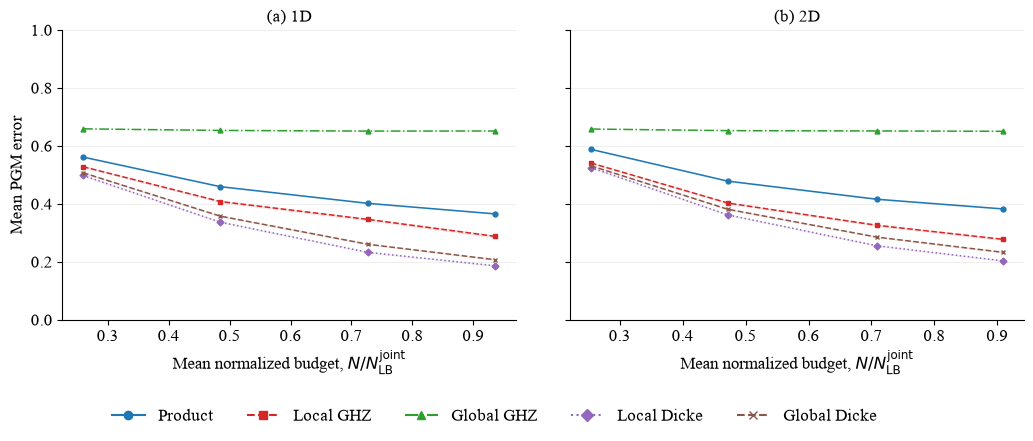

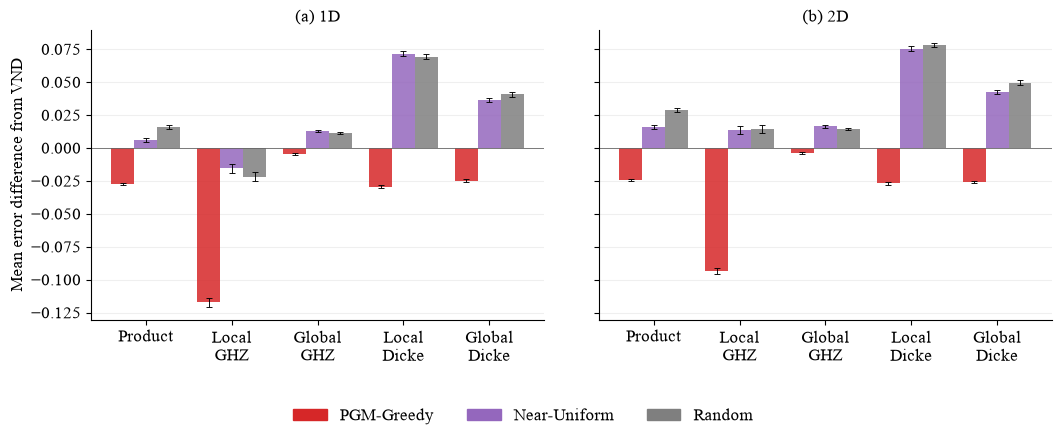

**Error bars:** 95% percentile bootstrap confidence intervals for the mean paired error difference from VND (2,000 resamples; field instances stratified by K, M, and field family). Budgets are averaged within each instance. Negative differences indicate lower error than VND.

In [3]:
publication_figures = figures(report, STUDY, zoom=SHOW_ZOOM)
assert len(publication_figures) == 2
for figure in publication_figures:
    display(figure)
    plt.close(figure)

display(Markdown('**Error bars:** 95% percentile bootstrap confidence intervals for the mean paired error difference from VND (2,000 resamples; field instances stratified by K, M, and field family). Budgets are averaged within each instance. Negative differences indicate lower error than VND.'))


## Numerical summaries

Overall/family error gaps, runtimes and completion coverage. Error ties use tolerance $10^{-7}$; equal errors need not imply equal allocations.


In [4]:
def show_table(rows):
    if not rows: print('No complete results'); return
    keys=list(rows[0]);lines=['| '+' | '.join(keys)+' |','| '+' | '.join(['---']*len(keys))+' |']
    for row in rows:
        lines.append('| '+' | '.join(f'{row[k]:.6g}' if isinstance(row[k],float) else str(row[k]) for k in keys)+' |')
    display(Markdown('\n'.join(lines)))

In [ ]:
for overall, heading in [(True, 'Overall summary'), (False, 'Field-family summary')]:
    display(Markdown('## '+heading))
    for key, title in [('quality', 'Error and gap summary'),
                       ('runtime', 'Runtime (seconds)'),
                       ('outcomes', 'VND versus Greedy')]:
        rows = [row for row in report[key] if (row['family'] == 'Overall') == overall]
        if overall:
            rows = [{k:v for k,v in row.items() if k != 'family'} for row in rows]
        display(Markdown('### '+title))
        show_table(rows)
